In [1]:
tables = spark.sql("SHOW TABLES").filter("isTemporary = false").collect()

for table in sorted(tables, key=lambda t: t.tableName):
    name = table.tableName
    rows = spark.table(f"`{name}`").count()
    print(f"{name:45} {rows:>10,} rows")

olist_customers_dataset                           99,441 rows
olist_geolocation_dataset                      1,000,163 rows
olist_order_items_dataset                        112,650 rows
olist_order_payments_dataset                     103,886 rows
olist_order_reviews_dataset                       99,224 rows
olist_orders_dataset                              99,441 rows
olist_products_dataset                            32,951 rows
olist_sellers_dataset                              3,095 rows
product_category_name_translation                     71 rows


In [2]:
from pyspark.sql import functions as F

orders = spark.table("olist_orders_dataset")

orders.select(
    F.count("*").alias("total_rows"),
    F.countDistinct("order_id").alias("unique_order_ids"),
    F.count(F.when(F.col("order_id").isNull(), 1)).alias("missing_order_ids")
).show()

+----------+----------------+-----------------+
|total_rows|unique_order_ids|missing_order_ids|
+----------+----------------+-----------------+
|     99441|           99441|                0|
+----------+----------------+-----------------+



In [3]:
orders_clean = (
    orders
    .withColumn("purchase_date", F.to_date("order_purchase_timestamp"))
    .withColumn("actual_date", F.to_date("order_delivered_customer_date"))
    .withColumn("estimated_date", F.to_date("order_estimated_delivery_date"))
)

can_compare = (
    (F.col("order_status") == "delivered")
    & F.col("actual_date").isNotNull()
    & F.col("estimated_date").isNotNull()
)

orders_clean = orders_clean.withColumn(
    "delivery_group",
    F.when(can_compare & (F.col("actual_date") > F.col("estimated_date")), "Late")
     .when(can_compare, "On time")
     .otherwise("Unknown")
)

orders_clean.groupBy("delivery_group").count().show()

+--------------+-----+
|delivery_group|count|
+--------------+-----+
|       On time|89936|
|       Unknown| 2971|
|          Late| 6534|
+--------------+-----+



In [4]:
orders_clean.write.format("delta").mode("overwrite").saveAsTable("silver_orders")

print("Original orders:", orders.count())
print("Silver orders:  ", spark.table("silver_orders").count())

Original orders: 99441
Silver orders:   99441


In [5]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

reviews = spark.table("olist_order_reviews_dataset")

reviews.groupBy("review_score").count().orderBy("review_score").show()

+------------+-----+
|review_score|count|
+------------+-----+
|           1|11424|
|           2| 3151|
|           3| 8179|
|           4|19142|
|           5|57328|
+------------+-----+



In [6]:
valid_reviews = (
    reviews
    .withColumn("review_score", F.expr("try_cast(review_score as int)"))
    .filter(F.col("review_score").between(1, 5))
    .filter(F.col("order_id").isNotNull())
)

review_order = Window.partitionBy("order_id").orderBy(
    F.to_timestamp("review_answer_timestamp").desc_nulls_last(),
    F.col("review_id").desc()
)

silver_reviews = (
    valid_reviews
    .withColumn("review_rank", F.row_number().over(review_order))
    .filter(F.col("review_rank") == 1)
    .drop("review_rank")
)

In [7]:
silver_reviews.write.format("delta").mode("overwrite").saveAsTable("silver_reviews")

saved = spark.table("silver_reviews")
print("Original review rows:", reviews.count())
print("Valid review rows:", valid_reviews.count())
print("Silver review rows:", saved.count())
print("Unique orders in Silver:", saved.select("order_id").distinct().count())

Original review rows: 99224
Valid review rows: 99224
Silver review rows: 98673
Unique orders in Silver: 98673


In [8]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark.sql("SHOW TABLES").select("tableName").show(100, truncate=False)

names = {
    "items": "olist_order_items_dataset",
    "customers": "olist_customers_dataset",
    "sellers": "olist_sellers_dataset",
    "products": "olist_products_dataset",
    "payments": "olist_order_payments_dataset",
    "geo": "olist_geolocation_dataset",
    "translation": "product_category_name_translation",
    "raw_reviews": "olist_order_reviews_dataset"
}

def read_source(key):
    return spark.table(names[key])

def save_table(data, table_name):
    data.write.format("delta").mode("overwrite").saveAsTable(table_name)

orders = spark.table("silver_orders")
reviews = spark.table("silver_reviews")

+---------------------------------+
|tableName                        |
+---------------------------------+
|olist_customers_dataset          |
|olist_geolocation_dataset        |
|olist_order_items_dataset        |
|olist_order_payments_dataset     |
|olist_order_reviews_dataset      |
|olist_orders_dataset             |
|olist_products_dataset           |
|olist_sellers_dataset            |
|product_category_name_translation|
|silver_orders                    |
|silver_reviews                   |
+---------------------------------+



In [9]:
items = (
    read_source("items")
    .withColumn("price", F.expr("try_cast(price as decimal(14,2))"))
    .withColumn("freight_value", F.expr("try_cast(freight_value as decimal(14,2))"))
)

customers = (
    read_source("customers")
    .withColumn("customer_state", F.upper(F.trim("customer_state")))
    .withColumn("customer_city", F.trim("customer_city"))
)

sellers = (
    read_source("sellers")
    .withColumn("seller_state", F.upper(F.trim("seller_state")))
    .withColumn("seller_city", F.trim("seller_city"))
)

products = (
    read_source("products")
    .withColumn("product_category_name", F.trim("product_category_name"))
)

payments = read_source("payments").withColumn(
    "payment_value", F.expr("try_cast(payment_value as decimal(14,2))")
)

geo = (
    read_source("geo")
    .withColumn("geolocation_state", F.upper(F.trim("geolocation_state")))
    .withColumn("geolocation_city", F.trim("geolocation_city"))
)

translation = (
    read_source("translation")
    .select("product_category_name", "product_category_name_english")
    .withColumn("product_category_name", F.trim("product_category_name"))
    .withColumn("product_category_name_english", F.trim("product_category_name_english"))
)

for data, table_name in [
    (items, "silver_items"),
    (customers, "silver_customers"),
    (sellers, "silver_sellers"),
    (products, "silver_products"),
    (payments, "silver_payments"),
    (geo, "silver_geolocation"),
    (translation, "silver_category_translation")
]:
    save_table(data, table_name)
    print(table_name, data.count())

silver_items 112650
silver_customers 99441
silver_sellers 3095
silver_products 32951
silver_payments 103886
silver_geolocation 1000163
silver_category_translation 71


In [10]:
def duplicate_key_groups(data, keys):
    return (
        data.groupBy(*keys)
        .count()
        .filter(F.col("count") > 1)
        .count()
    )

def unmatched_rows(left, right, key):
    return left.join(right.select(key).distinct(), key, "left_anti").count()

checks = [
    ("Orders: duplicate order IDs", duplicate_key_groups(orders, ["order_id"])),
    ("Orders: missing order ID", orders.filter("order_id IS NULL").count()),
    ("Orders: missing actual delivery date", orders.filter("actual_date IS NULL").count()),
    ("Orders: unknown delivery outcome", orders.filter("delivery_group = 'Unknown'").count()),
    ("Orders: no selected valid review", unmatched_rows(orders, reviews, "order_id")),
    ("Orders: unmatched customer", unmatched_rows(orders, customers, "customer_id")),
    ("Items: duplicate order/item keys", duplicate_key_groups(items, ["order_id", "order_item_id"])),
    ("Items: missing price", items.filter("price IS NULL").count()),
    ("Items: negative price", items.filter("price < 0").count()),
    ("Items: unmatched order", unmatched_rows(items, orders, "order_id")),
    ("Items: unmatched product", unmatched_rows(items, products, "product_id")),
    ("Items: unmatched seller", unmatched_rows(items, sellers, "seller_id")),
    ("Customers: duplicate IDs", duplicate_key_groups(customers, ["customer_id"])),
    ("Sellers: duplicate IDs", duplicate_key_groups(sellers, ["seller_id"])),
    ("Products: duplicate IDs", duplicate_key_groups(products, ["product_id"])),
    ("Translation: duplicate categories",
     duplicate_key_groups(translation, ["product_category_name"])),
    ("Payments: missing amount", payments.filter("payment_value IS NULL").count())
]

quality = spark.createDataFrame(checks, ["check_name", "issue_count"])
save_table(quality, "QualityChecks")
quality.show(50, truncate=False)

+------------------------------------+-----------+
|check_name                          |issue_count|
+------------------------------------+-----------+
|Orders: duplicate order IDs         |0          |
|Orders: missing order ID            |0          |
|Orders: missing actual delivery date|2965       |
|Orders: unknown delivery outcome    |2971       |
|Orders: no selected valid review    |768        |
|Orders: unmatched customer          |0          |
|Items: duplicate order/item keys    |0          |
|Items: missing price                |0          |
|Items: negative price               |0          |
|Items: unmatched order              |0          |
|Items: unmatched product            |0          |
|Items: unmatched seller             |0          |
|Customers: duplicate IDs            |0          |
|Sellers: duplicate IDs              |0          |
|Products: duplicate IDs             |0          |
|Translation: duplicate categories   |0          |
|Payments: missing amount      

In [11]:
region_states = {
    "North": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Northeast": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Central-West": ["DF", "GO", "MT", "MS"],
    "Southeast": ["ES", "MG", "RJ", "SP"],
    "South": ["PR", "RS", "SC"]
}

region_rows = [
    (state, region)
    for region, states in region_states.items()
    for state in states
]

region_map = spark.createDataFrame(region_rows, ["customer_state", "Region"])

dim_customer = (
    customers.select("customer_id", "customer_unique_id", "customer_city", "customer_state")
    .join(region_map, "customer_state", "left")
    .fillna({"Region": "Unknown"})
)

dim_seller = sellers.select("seller_id", "seller_city", "seller_state")

dim_product = (
    products.select("product_id", "product_category_name")
    .join(translation, "product_category_name", "left")
    .fillna({"product_category_name_english": "Unknown"})
)

save_table(dim_customer, "DimCustomer")
save_table(dim_seller, "DimSeller")
save_table(dim_product, "DimProduct")

In [12]:
fact_orders = (
    orders.select("order_id", "customer_id", "order_status", "purchase_date",
                  "actual_date", "estimated_date", "delivery_group")
    .join(reviews.select("order_id", "review_score"), "order_id", "left")
)

fact_items = (
    items.select("order_id", "order_item_id", "product_id", "seller_id",
                 "price", "freight_value")
    .join(
        orders.select("order_id", "customer_id", "purchase_date", "order_status"),
        "order_id", "left"
    )
)

assert fact_orders.count() == orders.count(), "Order join ne rows change kar di hain"
assert fact_items.count() == items.count(), "Item join ne rows change kar di hain"

save_table(fact_orders, "FactOrders")
save_table(fact_items, "FactOrderItems")

print("FactOrders:", fact_orders.count())
print("FactOrderItems:", fact_items.count())

FactOrders: 99441
FactOrderItems: 112650


In [13]:
date_range = orders.select(
    F.min("purchase_date").alias("first_date"),
    F.max("purchase_date").alias("last_date")
)

dim_date = (
    date_range.select(
        F.explode(F.expr("sequence(first_date, last_date, interval 1 day)")).alias("Date")
    )
    .withColumn("Year", F.year("Date"))
    .withColumn("MonthNumber", F.month("Date"))
    .withColumn("YearMonth", F.date_format("Date", "yyyy-MM"))
)

save_table(dim_date, "DimDate")

improvement = spark.range(0, 51).select(F.col("id").cast("int").alias("Percent"))
save_table(improvement, "Improvement")

In [14]:
analysis = fact_orders.filter(
    F.col("delivery_group").isin("Late", "On time")
    & F.col("review_score").between(1, 5)
)

comparison = (
    analysis.groupBy("delivery_group")
    .agg(
        F.count("*").alias("reviewed_orders"),
        F.round(F.avg("review_score"), 3).alias("average_score"),
        F.round(
            100 * F.avg((F.col("review_score") <= 2).cast("double")), 2
        ).alias("low_review_percent")
    )
)

comparison.show()
print("Excluded from review comparison:", fact_orders.count() - analysis.count())

+--------------+---------------+-------------+------------------+
|delivery_group|reviewed_orders|average_score|low_review_percent|
+--------------+---------------+-------------+------------------+
|       On time|          89443|         4.29|              9.27|
|          Late|           6381|         2.27|             62.42|
+--------------+---------------+-------------+------------------+

Excluded from review comparison: 3617


Late reviewed orders: 6381
On-time reviewed orders: 89443
Mann–Whitney U: 103305546.0
p-value: 0.0
Low-review gap in percentage points: 53.15


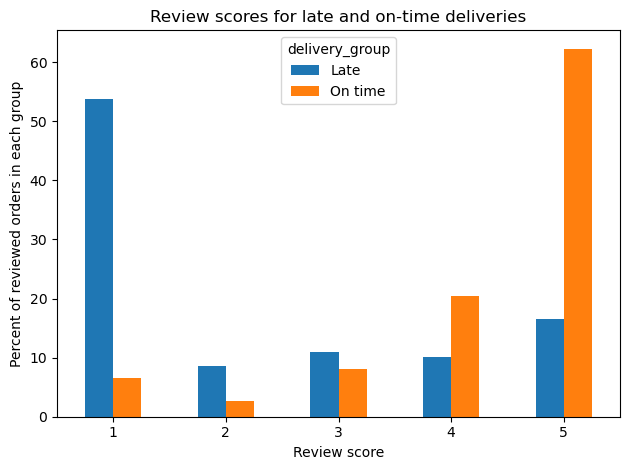

In [15]:
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import pandas as pd

scores = analysis.select("delivery_group", "review_score").toPandas()
late = scores.loc[scores["delivery_group"] == "Late", "review_score"]
on_time = scores.loc[scores["delivery_group"] == "On time", "review_score"]

test = mannwhitneyu(late, on_time, alternative="two-sided")

print("Late reviewed orders:", len(late))
print("On-time reviewed orders:", len(on_time))
print("Mann–Whitney U:", test.statistic)
print("p-value:", test.pvalue)

low_gap = 100 * ((late <= 2).mean() - (on_time <= 2).mean())
print("Low-review gap in percentage points:", round(low_gap, 2))

distribution = pd.crosstab(
    scores["review_score"], scores["delivery_group"], normalize="columns"
) * 100

distribution.plot(kind="bar", rot=0)
plt.xlabel("Review score")
plt.ylabel("Percent of reviewed orders in each group")
plt.title("Review scores for late and on-time deliveries")
plt.tight_layout()
plt.show()

In [16]:
state_summary = (
    fact_orders.join(
        dim_customer.select("customer_id", "customer_state"),
        "customer_id", "left"
    )
    .filter(F.col("delivery_group").isin("Late", "On time"))
    .groupBy("customer_state")
    .agg(
        F.count("*").alias("eligible_deliveries"),
        F.sum((F.col("delivery_group") == "Late").cast("int")).alias("late_orders"),
        F.round(100 * F.avg((F.col("delivery_group") == "Late").cast("double")), 2)
         .alias("late_rate_percent"),
        F.round(100 * F.avg((F.col("review_score") <= 2).cast("double")), 2)
         .alias("low_review_percent_among_reviewed")
    )
    .orderBy(F.desc("late_orders"))
)

state_summary.show(30, truncate=False)

+--------------+-------------------+-----------+-----------------+---------------------------------+
|customer_state|eligible_deliveries|late_orders|late_rate_percent|low_review_percent_among_reviewed|
+--------------+-------------------+-----------+-----------------+---------------------------------+
|SP            |40494              |1820       |4.49             |10.69                            |
|RJ            |12350              |1495       |12.11            |18.33                            |
|MG            |11354              |519        |4.57             |11.75                            |
|BA            |3256               |396        |12.16            |17.0                             |
|RS            |5344               |325        |6.08             |11.92                            |
|SC            |3546               |291        |8.21             |12.99                            |
|ES            |1995               |214        |10.73            |13.81                    

In [17]:
buyer_months = (
    fact_orders.filter(F.col("order_status") == "delivered")
    .join(dim_customer.select("customer_id", "customer_unique_id"), "customer_id")
    .filter(F.col("customer_unique_id").isNotNull() & F.col("purchase_date").isNotNull())
    .select("customer_unique_id", F.trunc("purchase_date", "month").alias("buy_month"))
    .distinct()
)

first_month = buyer_months.groupBy("customer_unique_id").agg(
    F.min("buy_month").alias("cohort_month")
)

activity = (
    buyer_months.join(first_month, "customer_unique_id")
    .withColumn("month_number", F.months_between("buy_month", "cohort_month").cast("int"))
)

cohort_sizes = first_month.groupBy("cohort_month").agg(
    F.count("*").alias("cohort_size")
)

active_counts = activity.groupBy("cohort_month", "month_number").agg(
    F.count("*").alias("active_buyers")
)

last_month = buyer_months.agg(F.max("buy_month")).first()[0]

cohort_grid = (
    cohort_sizes
    .withColumn("last_observed_month",
                F.months_between(F.lit(last_month), "cohort_month").cast("int"))
    .withColumn("month_number", F.explode(F.sequence(F.lit(0), F.col("last_observed_month"))))
    .drop("last_observed_month")
)

cohort = (
    cohort_grid.join(active_counts, ["cohort_month", "month_number"], "left")
    .fillna({"active_buyers": 0})
    .withColumn("retention_rate", F.col("active_buyers") / F.col("cohort_size"))
)

save_table(cohort, "CohortRetention")
cohort.orderBy("cohort_month", "month_number").show(20)

+------------+------------+-----------+-------------+--------------+
|cohort_month|month_number|cohort_size|active_buyers|retention_rate|
+------------+------------+-----------+-------------+--------------+
|  2016-09-01|           0|          1|            1|           1.0|
|  2016-09-01|           1|          1|            0|           0.0|
|  2016-09-01|           2|          1|            0|           0.0|
|  2016-09-01|           3|          1|            0|           0.0|
|  2016-09-01|           4|          1|            0|           0.0|
|  2016-09-01|           5|          1|            0|           0.0|
|  2016-09-01|           6|          1|            0|           0.0|
|  2016-09-01|           7|          1|            0|           0.0|
|  2016-09-01|           8|          1|            0|           0.0|
|  2016-09-01|           9|          1|            0|           0.0|
|  2016-09-01|          10|          1|            0|           0.0|
|  2016-09-01|          11|       